In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
# for dirname, _, filenames in os.walk('/kaggle/input'):
#     for filename in filenames:
#         print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

In [2]:
# --- CELL 1: SETUP & MASTER MODEL DEFINITION ---
import sys; import os; import random; import numpy as np; import pandas as pd
import torch; import torch.nn as nn; import torch.nn.functional as F; import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, Sampler
from torchvision import transforms
from PIL import Image
from tqdm import tqdm
from collections import OrderedDict
from sklearn.metrics import accuracy_score, roc_auc_score
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# ⚡️ CONTROL CENTER ⚡️
# ==========================================
RUN_MODE = 'PAD_KNOWN'       # RUN 1: 'ISIC_KNOWN' | RUN 2: 'PAD_KNOWN'
MAX_EPOCH = 30                
FORCE_FAIR_COMPARISON = True  # True = Limit both runs to ~450 labeled images
LABELED_RATIO=0.3
# SYSTEM
BATCH_SIZE = 32
MICRO_BATCH = 8
ACCUM_STEPS = BATCH_SIZE // MICRO_BATCH
CSV_PATH = '/kaggle/input/uni-split/master_ssl_split.csv' 
SAVE_DIR = f'./models_{RUN_MODE}'
CLIP_MEAN, CLIP_STD = (0.481, 0.457, 0.408), (0.268, 0.261, 0.275)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def set_seed(seed=2024):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed(seed)
set_seed()

if not os.path.exists('./ViT-B_16.pt'):
    os.system("wget https://openaipublic.azureedge.net/clip/models/5806e77cd80f8b59890b7e101eabd078d9fb84e6937f9e85e4ecb61988df416f/ViT-B-16.pt -O ./ViT-B_16.pt")

# --- 1. MODEL COMPONENTS ---
class LayerNorm(nn.LayerNorm):
    def forward(self, x): return super().forward(x.float()).type(x.dtype)

class QuickGELU(nn.Module):
    def forward(self, x): return x * torch.sigmoid(1.702 * x)

class ResidualAttentionBlock(nn.Module):
    def __init__(self, d_model, n_head):
        super().__init__()
        self.attn = nn.MultiheadAttention(d_model, n_head)
        self.ln_1 = LayerNorm(d_model)
        self.mlp = nn.Sequential(OrderedDict([("c_fc", nn.Linear(d_model, d_model*4)), ("gelu", QuickGELU()), ("c_proj", nn.Linear(d_model*4, d_model))]))
        self.ln_2 = LayerNorm(d_model)
        
    def forward(self, x):
        # Return FULL weights tuple (x, weights)
        attn_out, attn_weights = self.attn(x, x, x, need_weights=True)
        x = x + attn_out
        x = x + self.mlp(self.ln_2(x))
        return x, attn_weights 

class Transformer(nn.Module):
    def __init__(self, width, layers, heads):
        super().__init__()
        self.resblocks = nn.Sequential(*[ResidualAttentionBlock(width, heads) for _ in range(layers)])
    def forward(self, x):
        last_attn = None
        for layer in self.resblocks: x, last_attn = layer(x)
        return x, last_attn

class VisionTransformer(nn.Module):
    def __init__(self, input_resolution, patch_size, width, layers, heads, output_dim):
        super().__init__()
        self.conv1 = nn.Conv2d(3, width, patch_size, patch_size, bias=False)
        scale = width ** -0.5
        self.class_embedding = nn.Parameter(scale * torch.randn(width))
        self.positional_embedding = nn.Parameter(scale * torch.randn((input_resolution//patch_size)**2 + 1, width))
        self.ln_pre = LayerNorm(width)
        self.transformer = Transformer(width, layers, heads)
        self.ln_post = LayerNorm(width)
        self.proj = nn.Parameter(scale * torch.randn(width, output_dim)) # Projection layer

    def forward(self, x):
        x = self.conv1(x)
        x = x.reshape(x.shape[0], x.shape[1], -1).permute(0, 2, 1)
        x = torch.cat([self.class_embedding.to(x.dtype) + torch.zeros(x.shape[0], 1, x.shape[-1], dtype=x.dtype, device=x.device), x], dim=1)
        x = x + self.positional_embedding.to(x.dtype)
        x = self.ln_pre(x).permute(1, 0, 2)
        x, last_attn = self.transformer(x)
        x = x.permute(1, 0, 2)
        x = self.ln_post(x[:, 0, :])
        if self.proj is not None: x = x @ self.proj
        return x, last_attn

class FastPhysicsGate(nn.Module):
    def __init__(self, input_dim=512, project_dim=64, momentum=0.9): 
        super().__init__()
        self.momentum = momentum
        self.compressor = nn.Linear(input_dim, project_dim, bias=False)
        self.register_buffer("ref_cov", torch.eye(project_dim))
        self.register_buffer("ref_entropy", torch.tensor(1.0))
        self.register_buffer("ref_gini", torch.tensor(0.5))
    def _compute_stats(self, z):
        z = z.float(); n, d = z.size()
        mu = z.mean(dim=0, keepdim=True)
        cov = torch.mm((z - mu).t(), (z - mu)) / (n - 1 + 1e-6)
        try:
            cov_stable = cov + 1e-3 * torch.eye(d, device=z.device)
            L, _ = torch.linalg.eigh(cov_stable); L = L.clamp(min=1e-8); p = L / L.sum()
            entropy = -torch.sum(p * torch.log(p))
        except: entropy = torch.tensor(0.0, device=z.device)
        return cov, entropy
    def forward(self, features, attn_map=None, is_labeled=False):
        z_proj = self.compressor(features)
        cov, entropy = self._compute_stats(z_proj)
        if attn_map is not None:
            x = torch.abs(attn_map.float() + 1e-8); x_sorted, _ = torch.sort(x, dim=-1); n = x.size(-1)
            idx = torch.arange(1, n+1, device=x.device, dtype=torch.float32)
            gini = (torch.sum((2*idx - n - 1) * x_sorted, dim=-1) / (n * torch.sum(x_sorted, dim=-1))).mean()
        else: gini = self.ref_gini
        if is_labeled:
            with torch.no_grad():
                self.ref_cov = self.momentum * self.ref_cov + (1 - self.momentum) * cov
                self.ref_entropy = self.momentum * self.ref_entropy + (1 - self.momentum) * entropy
                self.ref_gini = self.momentum * self.ref_gini + (1 - self.momentum) * gini
            return None
        else:
            Z_H = torch.abs(entropy - self.ref_entropy) / (self.ref_entropy + 1e-6)
            Z_G = torch.abs(gini - self.ref_gini) / (self.ref_gini + 1e-6)
            gate = torch.exp(-(Z_H**2 + Z_G**2))
            return gate

# --- 2. MASTER CLASS (FIXED INIT) ---
class UCS_ViT_Final(nn.Module):
    def __init__(self, num_classes=5, input_size=320): # <--- Fixed Argument
        super().__init__()
        try: state = torch.jit.load('./ViT-B_16.pt', map_location="cpu").state_dict()
        except: state = torch.load('./ViT-B_16.pt', map_location="cpu")
        
        # Initialize with input_resolution=input_size
        self.encoder = VisionTransformer(input_resolution=input_size, patch_size=16, width=768, layers=12, heads=12, output_dim=512)
        
        new_state = {}
        for k, v in state.items():
            if k.startswith('visual.'): new_state[k.replace('visual.', '')] = v.float()
        
        if 'positional_embedding' in new_state:
            old_pos = new_state['positional_embedding']
            if old_pos.size(0) != self.encoder.positional_embedding.size(0):
                 cls, grid = old_pos[0:1], old_pos[1:]
                 grid = grid.reshape(1, 14, 14, -1).permute(0, 3, 1, 2)
                 grid = F.interpolate(grid, size=(input_size//16, input_size//16), mode='bicubic', align_corners=False)
                 new_state['positional_embedding'] = torch.cat([cls, grid.permute(0, 2, 3, 1).reshape(-1, 768)], dim=0)
        
        self.encoder.load_state_dict(new_state, strict=False)
        self.head = nn.Linear(512, num_classes)
        self.physics = FastPhysicsGate(input_dim=512, project_dim=64, momentum=0.9)

    def forward(self, x):
        feats, attn = self.encoder(x)
        feats = F.normalize(feats, dim=1)
        logits = self.head(feats)
        return logits, feats, attn

--2026-01-31 05:55:07--  https://openaipublic.azureedge.net/clip/models/5806e77cd80f8b59890b7e101eabd078d9fb84e6937f9e85e4ecb61988df416f/ViT-B-16.pt
Resolving openaipublic.azureedge.net (openaipublic.azureedge.net)... 13.107.246.73, 13.107.213.73, 2620:1ec:bdf::73, ...
Connecting to openaipublic.azureedge.net (openaipublic.azureedge.net)|13.107.246.73|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 350837078 (335M) [application/octet-stream]
Saving to: ‘./ViT-B_16.pt’

     0K .......... .......... .......... .......... ..........  0% 7.17M 47s
    50K .......... .......... .......... .......... ..........  0% 19.3M 32s
   100K .......... .......... .......... .......... ..........  0% 36.8M 24s
   150K .......... .......... .......... .......... ..........  0% 32.2M 21s
   200K .......... .......... .......... .......... ..........  0% 45.5M 18s
   250K .......... .......... .......... .......... ..........  0% 39.2M 17s
   300K .......... .......... ........

In [3]:
# --- CELL 2: DATASET (SYMMETRIC SCALED SPLIT) ---
# CONSTANTS
CLIP_MEAN_LOC = (0.481, 0.457, 0.408)
CLIP_STD_LOC = (0.268, 0.261, 0.275)

class UCSUnlabeledTransform:
    def __init__(self, image_size):
        self.weak = transforms.Compose([
            transforms.Resize(image_size), transforms.RandomHorizontalFlip(),
            transforms.ToTensor(), transforms.Normalize(CLIP_MEAN_LOC, CLIP_STD_LOC)])
        self.strong = transforms.Compose([
            transforms.Resize(image_size), transforms.RandomHorizontalFlip(),
            transforms.RandomAffine(15, (0.1, 0.1), (0.9, 1.1)),
            transforms.ColorJitter(0.4, 0.4, 0.4, 0.1),
            transforms.GaussianBlur(5, (0.1, 2.0)),
            transforms.ToTensor(), transforms.Normalize(CLIP_MEAN_LOC, CLIP_STD_LOC)])
    def __call__(self, x): return self.weak(x), self.strong(x)

class UniversalTrainDataset(Dataset):
    def __init__(self, labeled_df, unlabeled_df, image_size=(320, 320)):
        self.labeled_df = labeled_df.reset_index(drop=True)
        self.unlabeled_df = unlabeled_df.reset_index(drop=True)
        self.ucs_trans = UCSUnlabeledTransform(image_size)
        self.base_trans = transforms.Compose([
            transforms.Resize(image_size), transforms.RandomHorizontalFlip(),
            transforms.ToTensor(), transforms.Normalize(CLIP_MEAN_LOC, CLIP_STD_LOC)])
    def __len__(self): return len(self.labeled_df) + len(self.unlabeled_df)
    def __getitem__(self, idx):
        if idx < len(self.labeled_df):
            row = self.labeled_df.iloc[idx]
            try: img = Image.open(row['filepath']).convert('RGB')
            except: img = Image.new('RGB', (320, 320))
            return self.base_trans(img), row['true_label_shared'], 1
        else:
            row = self.unlabeled_df.iloc[idx - len(self.labeled_df)]
            try: img = Image.open(row['filepath']).convert('RGB')
            except: img = Image.new('RGB', (320, 320))
            w, s = self.ucs_trans(img)
            return (w, s), 5, 0

def ucs_collate_fn(batch):
    l_img, l_y, u_w, u_s = [], [], [], []
    for item in batch:
        data, target, flag = item
        if flag == 1: l_img.append(data); l_y.append(target)
        else: u_w.append(data[0]); u_s.append(data[1])
    return (torch.stack(l_img) if l_img else torch.empty(0),
            torch.tensor(l_y) if l_y else torch.empty(0),
            torch.stack(u_w) if u_w else torch.empty(0),
            torch.stack(u_s) if u_s else torch.empty(0))

def get_csv_splits(image_size, batch_size, labeled_ratio=0.3):
    print(f"Loading Split from {CSV_PATH}...")
    df_all = pd.read_csv(CSV_PATH)
    df_train = df_all[df_all['split'] == 'train'].reset_index(drop=True)
    
    # Sort by image_id to ensure SEQUENTIAL reproducibility
    df_train = df_train.sort_values('image_id')
    
    df_isic = df_train[df_train['dataset'] == 'ISIC']
    df_pad = df_train[df_train['dataset'] == 'PAD']
    
    # --- SYMMETRIC SCALING ---
    # We find the minimum size (which is PAD ~1474) and limit ISIC to that size.
    min_len = min(len(df_isic), len(df_pad))
    
    if FORCE_FAIR_COMPARISON:
        print(f"⚖️ SYMMETRIC MODE: Limiting datasets to first {min_len} images.")
        df_isic = df_isic.iloc[:min_len]
        df_pad = df_pad.iloc[:min_len]
    
    # Calculate Split Index
    n_lbl = int(min_len * labeled_ratio)
    
    if RUN_MODE == 'ISIC_KNOWN':
        # Labeled: First 30% of ISIC
        # Unlabeled: Remaining 70% of ISIC + All (Scaled) PAD
        lbl_df = df_isic.iloc[:n_lbl]
        unlbl_df = pd.concat([df_isic.iloc[n_lbl:], df_pad])
        
    elif RUN_MODE == 'PAD_KNOWN':
        # Labeled: First 30% of PAD
        # Unlabeled: Remaining 70% of PAD + All (Scaled) ISIC
        lbl_df = df_pad.iloc[:n_lbl]
        unlbl_df = pd.concat([df_pad.iloc[n_lbl:], df_isic])
        
    print(f"CONFIG [{RUN_MODE}]: {len(lbl_df)} Labeled | {len(unlbl_df)} Unlabeled")
    
    ds = UniversalTrainDataset(lbl_df, unlbl_df, image_size)
    p_len = len(lbl_df); s_len = len(unlbl_df)
    p_idxs = list(range(p_len)); s_idxs = list(range(p_len, p_len + s_len))
    lb = int(batch_size * 0.3); ub = batch_size - lb
    class UCS_Sampler(Sampler):
        def __iter__(self):
            p = np.random.permutation(p_idxs); s = np.random.permutation(s_idxs)
            while len(s) > ub:
                batch = []
                if len(p) < lb: p = np.random.permutation(p_idxs)
                batch.extend(p[:lb]); p = p[lb:]
                batch.extend(s[:ub]); s = s[ub:]
                yield batch
        def __len__(self): return len(s_idxs) // ub
        
    loader = DataLoader(ds, batch_sampler=UCS_Sampler(), num_workers=4, pin_memory=True, collate_fn=ucs_collate_fn)
    labels = lbl_df['true_label_shared'].values; counts = np.bincount(labels, minlength=5)
    weights = len(labels) / (5 * np.maximum(counts, 1))
    return loader, torch.FloatTensor(weights).to(device)

In [4]:
# # --- CELL 3: MODEL & PHYSICS (FIXED) ---
# from collections import OrderedDict

# # 1. ViT Helper Classes (Moved to Global Scope)
# class LayerNorm(nn.LayerNorm):
#     def forward(self, x): return super().forward(x.float()).type(x.dtype)

# class QuickGELU(nn.Module):
#     def forward(self, x): return x * torch.sigmoid(1.702 * x)

# class ResidualAttentionBlock(nn.Module):
#     def __init__(self, d_model, n_head):
#         super().__init__()
#         self.attn = nn.MultiheadAttention(d_model, n_head)
#         self.ln_1 = LayerNorm(d_model)
#         self.mlp = nn.Sequential(OrderedDict([
#             ("c_fc", nn.Linear(d_model, d_model * 4)),
#             ("gelu", QuickGELU()),
#             ("c_proj", nn.Linear(d_model * 4, d_model))
#         ]))
#         self.ln_2 = LayerNorm(d_model)

#     def attention(self, x):
#         self.attn_mask = None
#         return self.attn(x, x, x, need_weights=True)[0], self.attn(x, x, x, need_weights=True)[1]

#     def forward(self, x):
#         attn_out, weights = self.attention(self.ln_1(x))
#         x = x + attn_out
#         x = x + self.mlp(self.ln_2(x))
#         return x, weights

# class Transformer(nn.Module):
#     def __init__(self, width, layers, heads):
#         super().__init__()
#         self.width = width
#         self.layers = layers
#         self.resblocks = nn.Sequential(*[ResidualAttentionBlock(width, heads) for _ in range(layers)])

#     def forward(self, x):
#         last_attn_weights = None
#         for layer in self.resblocks:
#             x, weights = layer(x)
#             last_attn_weights = weights
#         return x, last_attn_weights

# class VisionTransformer(nn.Module):
#     def __init__(self, input_resolution, patch_size, width, layers, heads, output_dim):
#         super().__init__()
#         self.input_resolution = input_resolution
#         self.conv1 = nn.Conv2d(3, width, patch_size, patch_size, bias=False)
#         scale = width ** -0.5
#         self.class_embedding = nn.Parameter(scale * torch.randn(width))
#         self.positional_embedding = nn.Parameter(scale * torch.randn((input_resolution // patch_size) ** 2 + 1, width))
#         self.ln_pre = LayerNorm(width)
#         self.transformer = Transformer(width, layers, heads)
#         self.ln_post = LayerNorm(width)
#         self.proj = nn.Parameter(scale * torch.randn(width, output_dim))

#     def forward(self, x):
#         x = self.conv1(x)
#         x = x.reshape(x.shape[0], x.shape[1], -1).permute(0, 2, 1)
#         x = torch.cat([self.class_embedding.to(x.dtype) + torch.zeros(x.shape[0], 1, x.shape[-1], dtype=x.dtype, device=x.device), x], dim=1)
#         x = x + self.positional_embedding.to(x.dtype)
#         x = self.ln_pre(x).permute(1, 0, 2)
#         x, last_attn = self.transformer(x)
#         x = x.permute(1, 0, 2)
#         x = self.ln_post(x[:, 0, :])
#         if self.proj is not None: x = x @ self.proj
#         return x, last_attn

# # 2. Physics Gate
# class FastPhysicsGate(nn.Module):
#     def __init__(self, input_dim=512, project_dim=64, momentum=0.9): 
#         super().__init__()
#         self.momentum = momentum
#         self.compressor = nn.Linear(input_dim, project_dim, bias=False)
#         self.register_buffer("ref_cov", torch.eye(project_dim))
#         self.register_buffer("ref_entropy", torch.tensor(1.0))
#         self.register_buffer("ref_gini", torch.tensor(0.5))
    
#     def _compute_stats(self, z):
#         z = z.float()
#         n, d = z.size()
#         mu = z.mean(dim=0, keepdim=True)
#         cov = torch.mm((z - mu).t(), (z - mu)) / (n - 1 + 1e-6)
#         try:
#             cov_stable = cov + 1e-3 * torch.eye(d, device=z.device)
#             L, _ = torch.linalg.eigh(cov_stable)
#             L = L.clamp(min=1e-8)
#             p = L / L.sum()
#             entropy = -torch.sum(p * torch.log(p))
#             if torch.isnan(entropy): entropy = torch.tensor(0.0, device=z.device)
#         except: entropy = torch.tensor(0.0, device=z.device)
#         return cov, entropy

#     def forward(self, features, attn_map=None, is_labeled=False):
#         z_proj = self.compressor(features)
#         cov, entropy = self._compute_stats(z_proj)
        
#         if attn_map is not None:
#             x = torch.abs(attn_map.float() + 1e-8)
#             x_sorted, _ = torch.sort(x, dim=-1)
#             n = x.size(-1)
#             idx = torch.arange(1, n+1, device=x.device, dtype=torch.float32)
#             gini = (torch.sum((2*idx - n - 1) * x_sorted, dim=-1) / (n * torch.sum(x_sorted, dim=-1))).mean()
#             if torch.isnan(gini): gini = self.ref_gini
#         else: gini = self.ref_gini

#         if is_labeled:
#             with torch.no_grad():
#                 self.ref_cov = self.momentum * self.ref_cov + (1 - self.momentum) * cov
#                 self.ref_entropy = self.momentum * self.ref_entropy + (1 - self.momentum) * entropy
#                 self.ref_gini = self.momentum * self.ref_gini + (1 - self.momentum) * gini
#             return None
#         else:
#             Z_H = torch.abs(entropy - self.ref_entropy) / (self.ref_entropy + 1e-6)
#             Z_G = torch.abs(gini - self.ref_gini) / (self.ref_gini + 1e-6)
#             gate = torch.exp(-(Z_H**2 + Z_G**2))
#             if torch.isnan(gate): gate = torch.tensor(0.0, device=gate.device)
#             return gate

# # 3. Final Model
# class UCS_ViT_Final(nn.Module):
#     def __init__(self, num_classes=5):
#         super().__init__()
#         # Load Weights
#         try: state = torch.jit.load('./ViT-B_16.pt', map_location="cpu").state_dict()
#         except: state = torch.load('./ViT-B_16.pt', map_location="cpu")
        
#         # Now VisionTransformer is defined globally, so this works
#         self.encoder = VisionTransformer(input_resolution=320, patch_size=16, width=768, layers=12, heads=12, output_dim=512)
        
#         new_state = {}
#         for k, v in state.items():
#             if k.startswith('visual.'): new_state[k.replace('visual.', '')] = v.float()
        
#         if 'positional_embedding' in new_state:
#             old_pos = new_state['positional_embedding']
#             if old_pos.size(0) != self.encoder.positional_embedding.size(0):
#                  cls, grid = old_pos[0:1], old_pos[1:]
#                  grid = grid.reshape(1, 14, 14, -1).permute(0, 3, 1, 2)
#                  grid = F.interpolate(grid, size=(20, 20), mode='bicubic', align_corners=False)
#                  new_state['positional_embedding'] = torch.cat([cls, grid.permute(0, 2, 3, 1).reshape(-1, 768)], dim=0)
                 
#         self.encoder.load_state_dict(new_state, strict=False)
#         self.head = nn.Linear(512, num_classes)
#         self.physics = FastPhysicsGate(input_dim=512, project_dim=64, momentum=0.9)

#     def forward(self, x):
#         feats, attn = self.encoder(x)
#         feats = F.normalize(feats, dim=1)
#         logits = self.head(feats)
#         return logits, feats, attn

# print("Model Loaded.")

In [5]:
# --- CELL 4: TRAINING (SAVES 3 MODELS) ---
def train_ucs_negative_learning_lite():
    os.makedirs(SAVE_DIR, exist_ok=True)
    print(f"Initializing Data (Mode: {RUN_MODE}, Epochs: {MAX_EPOCH})...")
    
    train_loader, class_weights = get_csv_splits((320, 320), MICRO_BATCH, labeled_ratio=LABELED_RATIO)
    
    df_all = pd.read_csv(CSV_PATH)
    df_val = df_all[df_all['split'] == 'val'].reset_index(drop=True)
    val_ds = UniversalTrainDataset(df_val, pd.DataFrame(), image_size=(320, 320))
    val_loader = DataLoader(val_ds, batch_size=32, shuffle=False, num_workers=4)
    
    model = UCS_ViT_Final(num_classes=5, input_size=320).to(device)
    optimizer = optim.AdamW(model.parameters(), lr=5e-5, weight_decay=1e-2)
    scaler = torch.amp.GradScaler('cuda')
    ce_weighted = nn.CrossEntropyLoss(weight=class_weights)
    
    print(f"Starting Training in {SAVE_DIR}...")
    
    best_train_loss = float('inf')
    best_val_loss = float('inf')
    best_val_acc = 0.0
    
    for epoch in range(MAX_EPOCH):
        model.train()
        pbar = tqdm(enumerate(train_loader), total=len(train_loader), desc=f"Epoch {epoch+1}")
        running_gate = 0.0; running_train_loss = 0.0; num_batches = 0
        
        for batch_idx, batch in pbar:
            l_img, l_y, u_w, u_s = batch
            l_img = l_img.to(device); l_y = l_y.to(device)
            u_w = u_w.to(device); u_s = u_s.to(device)
            if u_w.size(0) < 2: continue
            
            with torch.amp.autocast('cuda'):
                loss = torch.tensor(0.0).to(device)
                if l_img.size(0) > 0:
                    l_logits, l_feats, l_attn = model(l_img)
                    loss += ce_weighted(l_logits, l_y)
                    if batch_idx % (15 * ACCUM_STEPS) == 0:
                        with torch.amp.autocast('cuda', enabled=False):
                            model.physics(l_feats.float().detach(), l_attn[:, 0, 1:].detach(), is_labeled=True)
                
                u_logits_w, u_feats_w, u_attn_w = model(u_w)
                with torch.amp.autocast('cuda', enabled=False):
                    gate_w = model.physics(u_feats_w.float().detach(), u_attn_w[:, 0, 1:].detach(), is_labeled=False)
                running_gate = 0.9 * running_gate + 0.1 * gate_w.mean().item()
                
                u_logits_s, _, _ = model(u_s)
                probs_w = torch.softmax(u_logits_w, dim=1); max_probs, pseudo_lbl = torch.max(probs_w, dim=1)
                mask_trust = gate_w.ge(0.5).float(); mask_conf = max_probs.ge(0.95).float()
                
                if (mask_trust*mask_conf).sum() > 0:
                    loss += 1.0 * (F.cross_entropy(u_logits_s, pseudo_lbl, reduction='none') * (mask_trust*mask_conf)).mean()
                if ((1-mask_trust)*mask_conf).sum() > 0:
                    probs_s = torch.softmax(u_logits_s, dim=1)
                    loss += 0.5 * (F.kl_div(torch.log(probs_s+1e-8), torch.ones_like(probs_s)/5.0, reduction='none').sum(1) * ((1-mask_trust)*mask_conf)).mean()
                
                running_train_loss += loss.item()
                num_batches += 1
                loss = loss / ACCUM_STEPS

            scaler.scale(loss).backward()
            if (batch_idx + 1) % ACCUM_STEPS == 0:
                scaler.unscale_(optimizer); torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); scaler.step(optimizer); scaler.update(); optimizer.zero_grad()
            pbar.set_postfix({'Gate': f"{running_gate:.2f}", 'Loss': f"{loss.item()*ACCUM_STEPS:.2f}"})
        
        # VALIDATION & SAVING (3 MODELS)
        avg_train_loss = running_train_loss / max(num_batches, 1)
        model.eval(); val_loss = 0.0; val_preds, val_targets, val_scores = [], [], []
        with torch.no_grad():
            for img, label, _ in val_loader:
                img = img.to(device); label = label.to(device)
                logits, feats, attn = model(img)
                val_loss += ce_weighted(logits, label).item()
                gate = model.physics(feats, attn[:, 0, 1:], is_labeled=False)
                val_scores.extend([gate.item()]*len(label)); val_preds.extend(torch.argmax(logits, 1).cpu().numpy()); val_targets.extend(label.cpu().numpy())
        val_loss /= len(val_loader)
        thresh = np.median(val_scores); final_preds = [p if s >= thresh else 5 for p, s in zip(val_preds, val_scores)]; univ_acc = accuracy_score(val_targets, final_preds)
        print(f"Ep {epoch+1} | Train: {avg_train_loss:.4f} | Val: {val_loss:.4f} | Acc: {univ_acc*100:.2f}%")
        
        if avg_train_loss < best_train_loss:
            best_train_loss = avg_train_loss; torch.save(model.state_dict(), os.path.join(SAVE_DIR, 'best_model_train_loss.pth'))
        if val_loss < best_val_loss:
            best_val_loss = val_loss; torch.save(model.state_dict(), os.path.join(SAVE_DIR, 'best_model_val_loss.pth'))
        if univ_acc > best_val_acc:
            best_val_acc = univ_acc; torch.save(model.state_dict(), os.path.join(SAVE_DIR, 'best_model_val_acc.pth'))

if __name__ == "__main__":
    train_ucs_negative_learning_lite()

Initializing Data (Mode: PAD_KNOWN, Epochs: 30)...
Loading Split from /kaggle/input/uni-split/master_ssl_split.csv...
⚖️ SYMMETRIC MODE: Limiting datasets to first 1474 images.
CONFIG [PAD_KNOWN]: 442 Labeled | 2506 Unlabeled
Starting Training in ./models_PAD_KNOWN...


Epoch 1: 100%|██████████| 417/417 [01:55<00:00,  3.63it/s, Gate=0.64, Loss=1.51]


Ep 1 | Train: 1.4884 | Val: 1.9759 | Acc: 7.19%


Epoch 2: 100%|██████████| 417/417 [01:52<00:00,  3.70it/s, Gate=0.89, Loss=1.30]


Ep 2 | Train: 1.4438 | Val: 1.9689 | Acc: 10.79%


Epoch 3: 100%|██████████| 417/417 [01:53<00:00,  3.69it/s, Gate=0.85, Loss=1.31]


... (51 outputs left out)

Epoch 29: 100%|██████████| 417/417 [01:53<00:00,  3.69it/s, Gate=0.99, Loss=0.57]


Ep 29 | Train: 0.8829 | Val: 2.0999 | Acc: 17.08%


Epoch 30: 100%|██████████| 417/417 [01:53<00:00,  3.68it/s, Gate=0.98, Loss=0.60]


Ep 30 | Train: 0.8339 | Val: 2.2601 | Acc: 14.44%


Loading Test Split from /kaggle/input/uni-split/master_ssl_split.csv...

 >>> EVALUATING: best_model_train_loss.pth (PAD_KNOWN) <<<


100%|██████████| 1780/1780 [01:13<00:00, 24.15it/s]


Saved: preds_PAD_KNOWN_best_model_train_loss.csv
------------------------------
Threshold:     0.9387
Universal Acc: 13.93%
Closed-Set Acc:31.96%
OOD AUROC:     0.6546
------------------------------


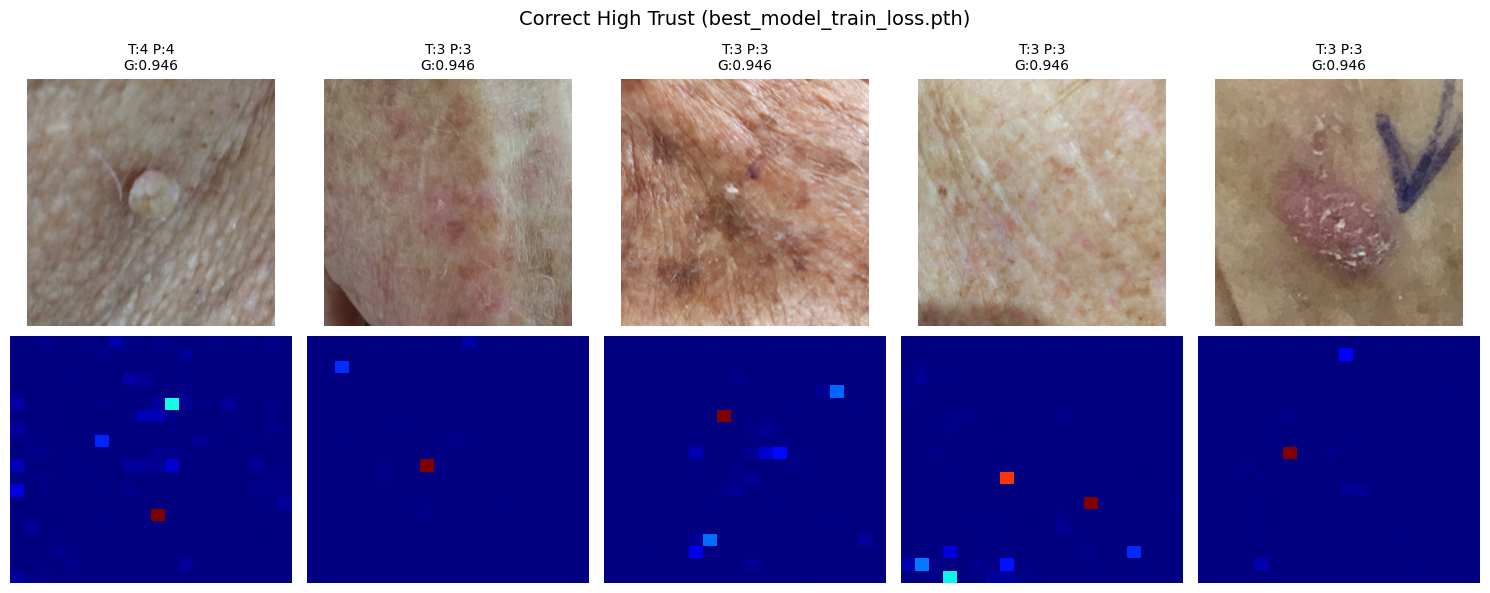

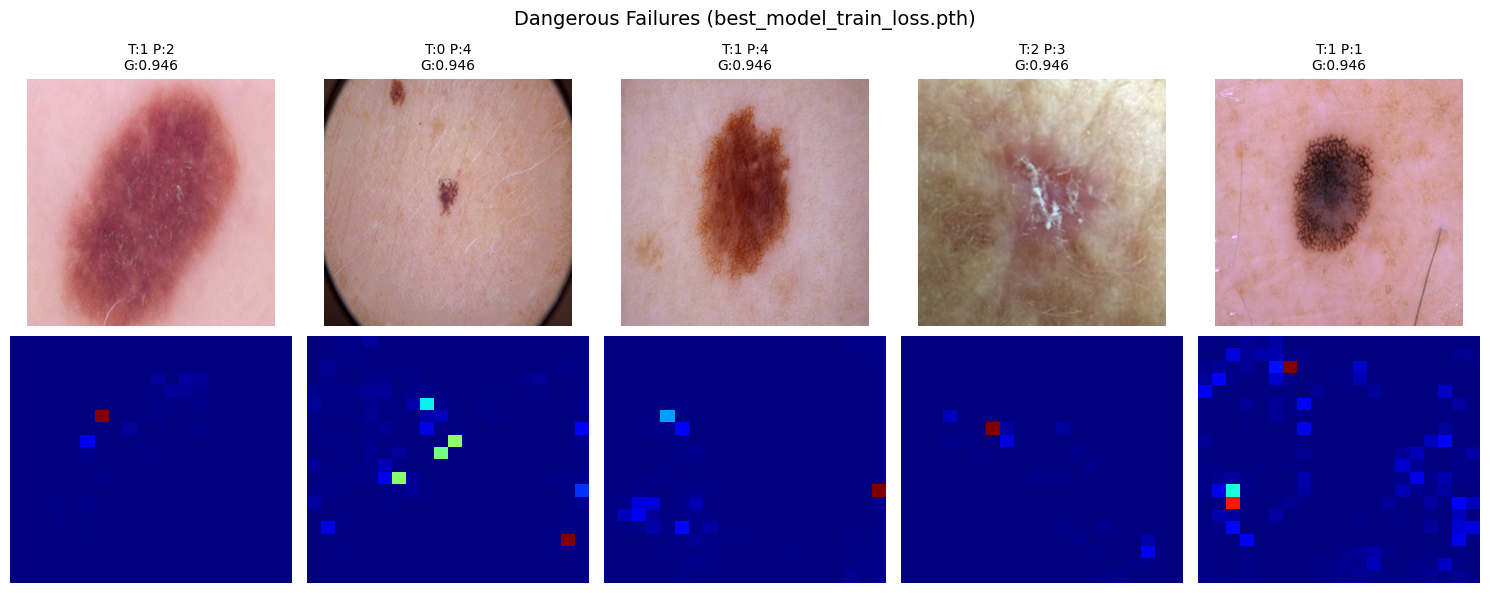


 >>> EVALUATING: best_model_val_loss.pth (PAD_KNOWN) <<<


100%|██████████| 1780/1780 [00:59<00:00, 29.92it/s]


Saved: preds_PAD_KNOWN_best_model_val_loss.csv
------------------------------
Threshold:     0.8327
Universal Acc: 9.61%
Closed-Set Acc:28.16%
OOD AUROC:     0.5185
------------------------------


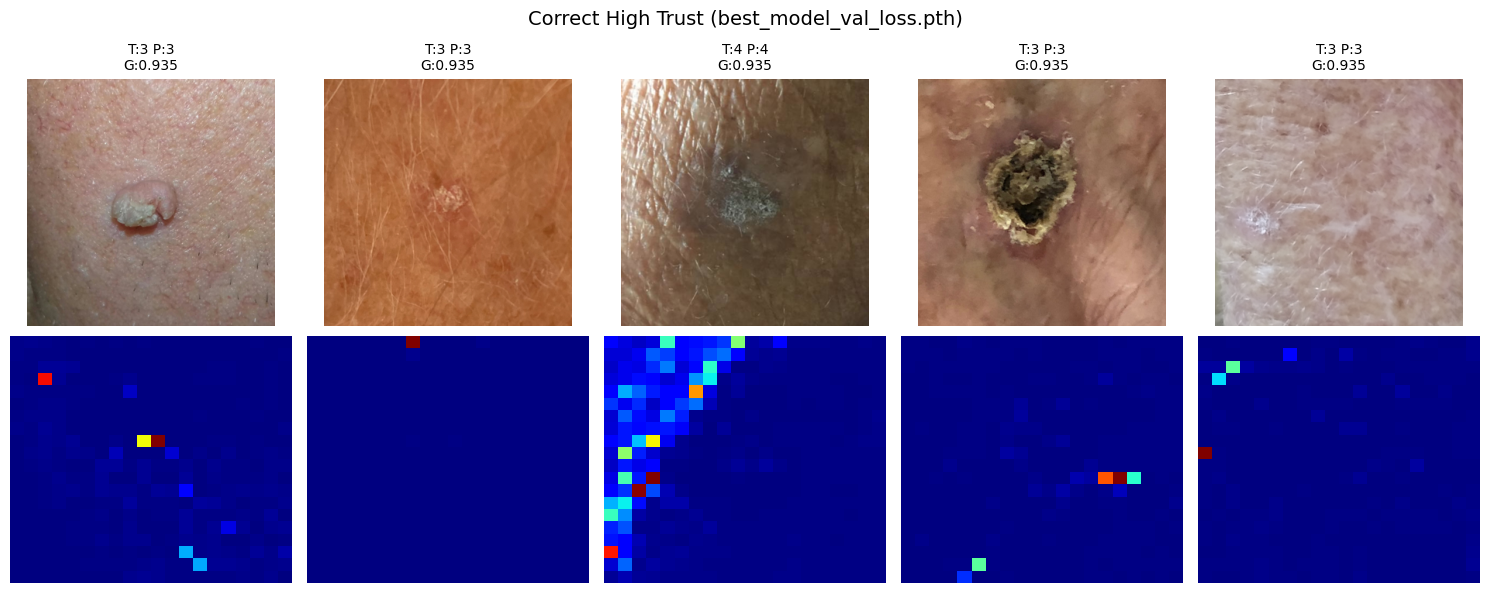

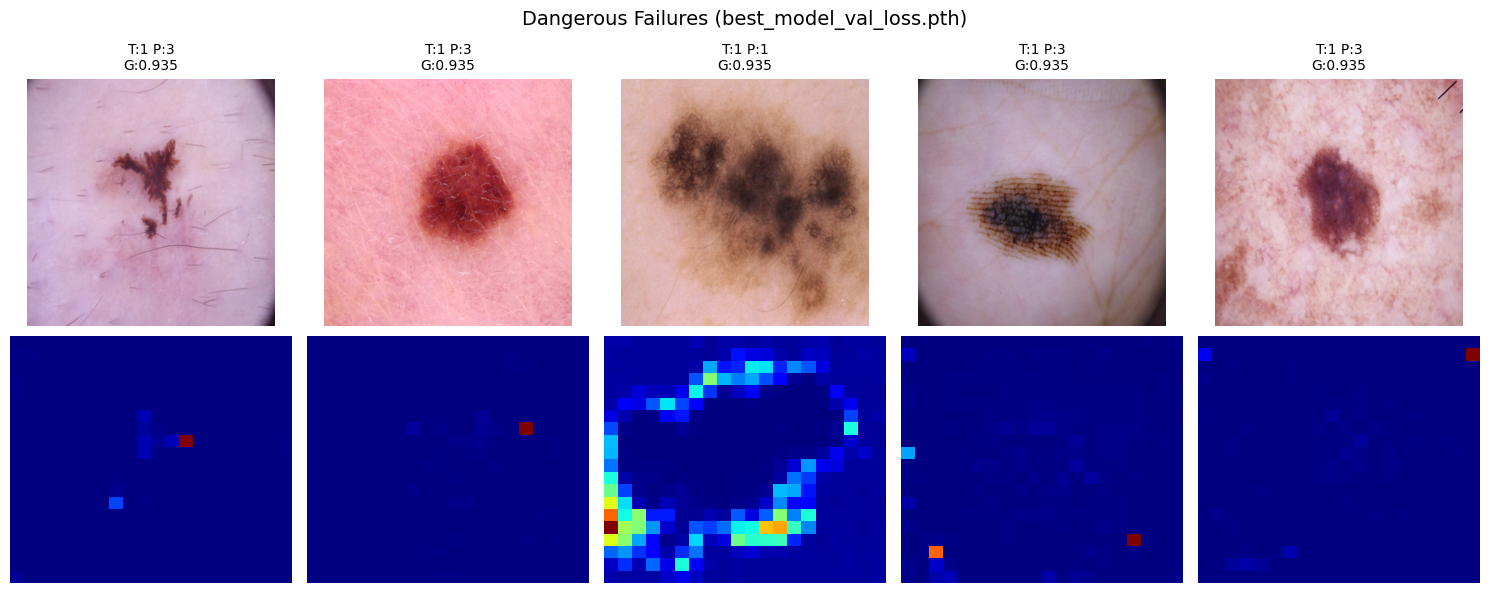


 >>> EVALUATING: best_model_val_acc.pth (PAD_KNOWN) <<<


100%|██████████| 1780/1780 [01:00<00:00, 29.65it/s]


Saved: preds_PAD_KNOWN_best_model_val_acc.csv
------------------------------
Threshold:     0.9582
Universal Acc: 17.64%
Closed-Set Acc:30.38%
OOD AUROC:     0.6118
------------------------------


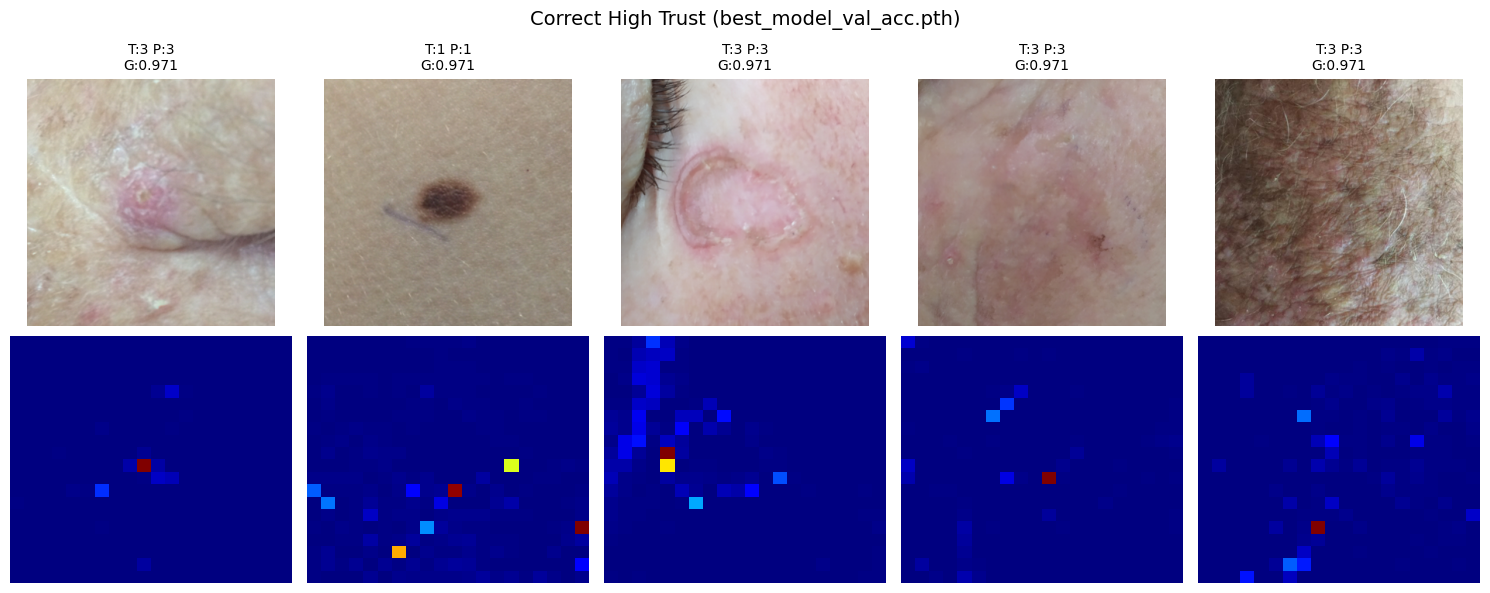

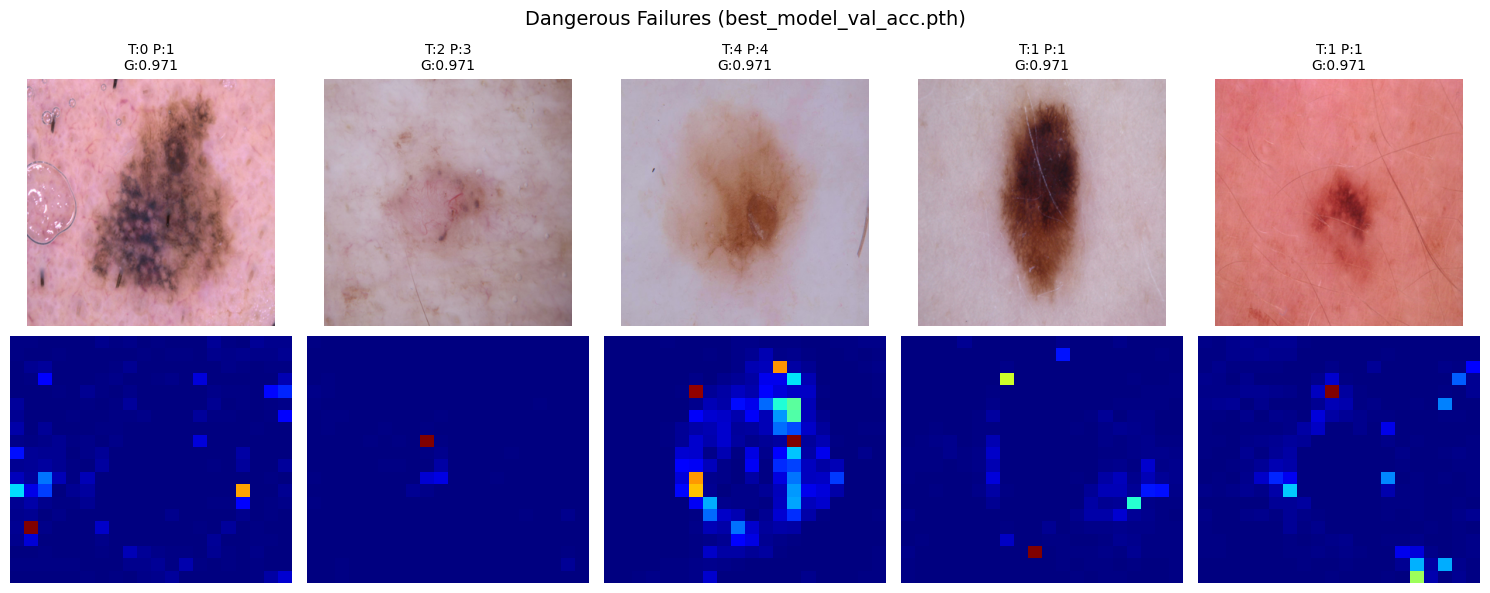

In [6]:
# --- CELL 5: EVALUATION (DETAILED METRICS) ---
def evaluate_all():
    # 1. Check Globals or Default
    try: mode = RUN_MODE
    except NameError: mode = 'ISIC_KNOWN'
    
    try: save_dir = SAVE_DIR
    except NameError: save_dir = f'./models_{mode}'

    MODELS = ['best_model_train_loss.pth', 'best_model_val_loss.pth', 'best_model_val_acc.pth']
    
    print(f"Loading Test Split from {CSV_PATH}...")
    df_all = pd.read_csv(CSV_PATH)
    df_test = df_all[df_all['split'] == 'test'].reset_index(drop=True)
    
    test_ds = UniversalTrainDataset(df_test, pd.DataFrame(), image_size=(320, 320))
    test_loader = DataLoader(test_ds, batch_size=1, shuffle=False)
    
    for mod in MODELS:
        path = os.path.join(save_dir, mod)
        if not os.path.exists(path): 
            print(f"Skipping {mod} (Not Found)")
            continue
            
        print(f"\n" + "="*50)
        print(f" >>> EVALUATING: {mod} ({mode}) <<<")
        print("="*50)
        
        model = UCS_ViT_Final(num_classes=5, input_size=320).to(device)
        model.load_state_dict(torch.load(path, map_location=device))
        model.eval()
        
        results = []
        with torch.no_grad():
            for idx, (img, label, _) in enumerate(tqdm(test_loader)):
                img = img.to(device)
                row = df_test.iloc[idx]
                
                # GROUND TRUTH LOGIC
                is_known = False
                if mode == 'ISIC_KNOWN' and row['dataset'] == 'ISIC': is_known = True
                elif mode == 'PAD_KNOWN' and row['dataset'] == 'PAD': is_known = True
                
                logits, feats, attn = model(img)
                gate = model.physics(feats, attn[:, 0, 1:], is_labeled=False)
                conf, pred = torch.max(torch.softmax(logits, 1), 1)
                
                attn_map = attn[0,0,1:].reshape(20, 20).cpu().numpy()
                
                results.append({
                    'image_id': row['image_id'], 
                    'dataset': row['dataset'], 
                    'true_label': label.item(), 
                    'pred_class': pred.item(), 
                    'gate_score': gate.item(), 
                    'is_known': is_known, 
                    'attn_map': attn_map, 
                    'filepath': row['filepath']
                })
        
        df_res = pd.DataFrame(results)
        
        # --- METRICS CALCULATION ---
        thresh = df_res['gate_score'].median()
        
        # 1. Final Prediction (Reject if < Thresh)
        df_res['final_pred'] = df_res.apply(lambda x: x['pred_class'] if x['gate_score'] >= thresh else 5, axis=1)
        
        # 2. Correctness Check
        # Known -> Must match True Label
        # Unknown -> Must be Rejected (5)
        df_res['is_correct'] = df_res.apply(lambda x: (x['final_pred'] == x['true_label']) if x['is_known'] else (x['final_pred'] == 5), axis=1)
        
        # 3. Save CSV
        csv_name = f'preds_{mode}_{mod.replace(".pth","")}.csv'
        df_res.drop(columns=['attn_map', 'filepath']).to_csv(csv_name, index=False)
        print(f"Saved: {csv_name}")
        
        # 4. Compute Accuracy Metrics
        univ_acc = accuracy_score(df_res['true_label'], df_res['final_pred'])
        
        known_subset = df_res[df_res['is_known'] == True]
        closed_acc = accuracy_score(known_subset['true_label'], known_subset['final_pred']) if len(known_subset) > 0 else 0.0
        
        # 5. Compute AUROC (OOD Detection Ability)
        y_true_binary = df_res['is_known'].astype(int)
        try: auroc = roc_auc_score(y_true_binary, df_res['gate_score'])
        except: auroc = 0.5
        
        print("-" * 30)
        print(f"Threshold:     {thresh:.4f}")
        print(f"Universal Acc: {univ_acc*100:.2f}%")
        print(f"Closed-Set Acc:{closed_acc*100:.2f}%")
        print(f"OOD AUROC:     {auroc:.4f}")
        print("-" * 30)
        
        # VISUALIZATION
        correct = df_res[(df_res['is_correct']) & (df_res['gate_score']>thresh)].sort_values('gate_score', ascending=False).head(5)
        wrong = df_res[~df_res['is_correct']].sort_values('gate_score', ascending=False).head(5)
        
        def viz(sub, title):
            if len(sub)==0: return
            plt.figure(figsize=(15, 6)); plt.suptitle(title, fontsize=14)
            for i, (ix, r) in enumerate(sub.iterrows()):
                try: img = Image.open(r['filepath']).convert('RGB').resize((320,320))
                except: continue
                plt.subplot(2, 5, i+1); plt.imshow(img); plt.axis('off')
                plt.title(f"T:{r['true_label']} P:{r['final_pred']}\nG:{r['gate_score']:.3f}", fontsize=10)
                plt.subplot(2, 5, i+6); sns.heatmap(r['attn_map'], cmap='jet', cbar=False, xticklabels=False, yticklabels=False); plt.axis('off')
            plt.tight_layout(); plt.show()
            
        viz(correct, f"Correct High Trust ({mod})")
        viz(wrong, f"Dangerous Failures ({mod})")

if __name__ == "__main__":
    evaluate_all()

In [7]:
# import os
# import sys
# import argparse
# import numpy as np
# import torch
# import torch.nn as nn
# import torch.nn.functional as F
# from torch.utils.data import DataLoader
# import matplotlib.pyplot as plt
# import seaborn as sns
# from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, precision_recall_fscore_support
# # from sklearn.manifold import TSNE
# from tqdm import tqdm

# # --- 1. Missing Helper Functions (Re-implemented using standard libs) ---
# def calculate_metrics(y_true, y_pred, y_prob):
#     """Standard metric calculation replacement."""
#     acc = accuracy_score(y_true, y_pred)
#     precision, recall, f1, _ = precision_recall_fscore_support(y_true, y_pred, average='macro', zero_division=0)
#     return {
#         'accuracy': acc,
#         'precision': precision,
#         'recall': recall,
#         'f1_score': f1
#     }

# def calculate_confusion_matrix(y_true, y_pred):
#     return confusion_matrix(y_true, y_pred)

# # --- 2. The Competitor's Plotting Functions (Exact Copy) ---
# def plot_confusion_matrix(cm: np.ndarray, class_names: list, save_path: str):
#     """Plot confusion matrix."""
#     plt.figure(figsize=(10, 8))
#     sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
#                 xticklabels=class_names, yticklabels=class_names)
#     plt.title('Confusion Matrix')
#     plt.xlabel('Predicted')
#     plt.ylabel('True')
#     plt.tight_layout()
#     plt.savefig(save_path, dpi=300, bbox_inches='tight')
#     plt.close()

# def plot_ukc_ukd_distribution(ukc_scores: np.ndarray, ukd_scores: np.ndarray, 
#                               labels: np.ndarray, save_path: str):
#     """Plot distribution of UKC and UKD scores."""
#     fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
    
#     unique_labels = np.unique(labels)
    
#     # UKC scores distribution (Semantic Uncertainty)
#     for i in unique_labels:
#         mask = (labels == i)
#         if np.sum(mask) > 0:
#             label_name = 'Unknown' if i >= 5 else f'Class {i}'
#             ax1.hist(ukc_scores[mask], alpha=0.5, label=label_name, bins=20, density=True)
    
#     ax1.set_xlabel('UKC Score (Proto Distance)')
#     ax1.set_ylabel('Density')
#     ax1.set_title('Distribution of UKC Scores')
#     ax1.legend()
    
#     # UKD scores distribution (Entropy/Uncertainty)
#     for i in unique_labels:
#         mask = (labels == i)
#         if np.sum(mask) > 0:
#             label_name = 'Unknown' if i >= 5 else f'Class {i}'
#             ax2.hist(ukd_scores[mask], alpha=0.5, label=label_name, bins=20, density=True)
    
#     ax2.set_xlabel('UKD Score (Entropy)')
#     ax2.set_ylabel('Density')
#     ax2.set_title('Distribution of UKD Scores')
#     ax2.legend()
    
#     plt.tight_layout()
#     plt.savefig(save_path, dpi=300, bbox_inches='tight')
#     plt.close()

# def plot_feature_visualization(features: np.ndarray, labels: np.ndarray, save_path: str):
#     """Visualize features using t-SNE."""
#     try:
#         print("Running t-SNE (this might take a moment)...")
#         # Subsample if too large for speed
#         if len(features) > 2000:
#             idx = np.random.choice(len(features), 2000, replace=False)
#             features = features[idx]
#             labels = labels[idx]

#         tsne = TSNE(n_components=2, random_state=42, perplexity=30, init='pca', learning_rate='auto')
#         features_2d = tsne.fit_transform(features)
        
#         plt.figure(figsize=(10, 8))
        
#         # Color map handling for Unknowns
#         unique_labels = np.unique(labels)
#         colors = plt.cm.tab10(np.linspace(0, 1, len(unique_labels)))
        
#         for i, lbl in enumerate(unique_labels):
#             mask = labels == lbl
#             label_name = 'Unknown' if lbl >= 5 else f'Class {lbl}'
#             plt.scatter(features_2d[mask, 0], features_2d[mask, 1], 
#                         label=label_name, alpha=0.6, s=20)

#         plt.title('t-SNE Visualization of Features')
#         plt.xlabel('t-SNE 1')
#         plt.ylabel('t-SNE 2')
#         plt.legend()
#         plt.tight_layout()
#         plt.savefig(save_path, dpi=300, bbox_inches='tight')
#         plt.close()
        
#     except ImportError:
#         print("sklearn not available, skipping t-SNE visualization")

# def print_classification_report(labels: np.ndarray, predictions: np.ndarray, class_names: list):
#     """Print detailed classification report."""
#     print("\n" + "="*50)
#     print("CLASSIFICATION REPORT")
#     print("="*50)
    
#     # Filter only known classes for report if needed, or map unknowns
#     # Here we map standard report
#     unique_preds = np.unique(predictions)
#     target_names = [class_names[i] for i in unique_preds if i < len(class_names)]
    
#     report = classification_report(labels, predictions, digits=4, zero_division=0)
#     print(report)

# def save_results(results: dict, save_dir: str):
#     """Save evaluation results."""
#     os.makedirs(save_dir, exist_ok=True)
    
#     # Save metrics
#     metrics_path = os.path.join(save_dir, 'metrics.txt')
#     with open(metrics_path, 'w') as f:
#         f.write("Evaluation Metrics:\n")
#         f.write("="*30 + "\n")
#         for key, value in results['metrics'].items():
#             f.write(f"{key}: {value:.4f}\n")
    
#     # Save confusion matrix
#     cm_path = os.path.join(save_dir, 'confusion_matrix.txt')
#     np.savetxt(cm_path, results['confusion_matrix'], fmt='%d')
    
#     # Save predictions
#     predictions_path = os.path.join(save_dir, 'predictions.npz')
#     np.savez(predictions_path,
#              predictions=results['predictions'],
#              labels=results['labels'],
#              probabilities=results['probabilities'],
#              ukc_scores=results['ukc_scores'],
#              ukd_scores=results['ukd_scores'])
    
#     print(f"Results saved to {save_dir}")

# # --- 3. The Bridge: evaluate_model adapted for YOUR Model ---
# def evaluate_model_bridge(model, test_loader, prototypes, device):
#     """
#     Adapts your ViT model to the competitor's evaluation logic.
#     MAPPING:
#     - UKC Score -> Euclidean distance to nearest Prototype (Semantic Uncertainty)
#     - UKD Score -> Entropy of Softmax Distribution (General Uncertainty)
#     """
#     model.eval()
    
#     all_predictions = []
#     all_labels = []
#     all_probabilities = []
#     all_features = []
#     all_ukc_scores = []
#     all_ukd_scores = []
    
#     print("Running Competitor Evaluation Loop...")
#     with torch.no_grad():
#         for x, y in tqdm(test_loader, desc='Evaluating'):
#             x = x.to(device)
            
#             # --- FORWARD PASS (Your Architecture) ---
#             # 1. Get Features
#             features = model.encoder(x)
#             features = F.normalize(features, dim=1)
            
#             # 2. Get Logits (Using the FC Head trained on labeled data)
#             logits, _, _, _, _ = model(x) # We just need the first output 'out'
#             probabilities = F.softmax(logits, dim=1)
            
#             # --- SCORING (The "Shift") ---
            
#             # UKC Calculation: Distance to Prototypes
#             # sim_matrix = features @ prototypes.t()
#             # dist_sq = 2 - 2 * sim_matrix
#             # min_dist, pred_idx = dist_sq.min(dim=1)
            
#             # Use Cosine Similarity directly as score (Higher = More Confident)
#             sim_matrix = torch.mm(features, prototypes.t())
#             max_sim, pred_idx = sim_matrix.max(dim=1)
            
#             # UKC Score: We treat 1 - max_sim as the "Uncertainty"
#             ukc_batch = 1.0 - max_sim
            
#             # UKD Calculation: Entropy
#             # H(p) = - sum(p * log(p))
#             ukd_batch = -torch.sum(probabilities * torch.log(probabilities + 1e-8), dim=1)

#             # Predictions (Closed Set)
#             predictions = pred_idx # Prediction based on nearest prototype is usually better for Open Set
            
#             # Store results
#             all_predictions.extend(predictions.cpu().numpy())
#             # For labels: Convert unknown classes (>=5) to a single '5' label for visualization if desired
#             y_np = y.numpy()
#             y_remapped = np.where(y_np >= 5, 5, y_np)
#             all_labels.extend(y_remapped)
            
#             all_probabilities.extend(probabilities.cpu().numpy())
#             all_features.extend(features.cpu().numpy())
#             all_ukc_scores.extend(ukc_batch.cpu().numpy())
#             all_ukd_scores.extend(ukd_batch.cpu().numpy())
    
#     # Convert to numpy arrays
#     all_predictions = np.array(all_predictions)
#     all_labels = np.array(all_labels)
#     all_probabilities = np.array(all_probabilities)
#     all_features = np.array(all_features)
#     all_ukc_scores = np.array(all_ukc_scores)
#     all_ukd_scores = np.array(all_ukd_scores)
    
#     # Calculate metrics (Only on Closed Set samples mostly, but let's do all)
#     metrics = calculate_metrics(all_labels, all_predictions, all_probabilities)
    
#     # Calculate confusion matrix
#     cm = calculate_confusion_matrix(all_labels, all_predictions)
    
#     return {
#         'metrics': metrics,
#         'confusion_matrix': cm,
#         'predictions': all_predictions,
#         'labels': all_labels,
#         'probabilities': all_probabilities,
#         'features': all_features,
#         'ukc_scores': all_ukc_scores,
#         'ukd_scores': all_ukd_scores
#     }

# # --- 4. Main Execution Block ---
# def run_competitor_test():
#     # SETUP
#     IMAGE_SIZE = (320, 320)
#     BATCH_SIZE = 32
#     KNOWN_CLASSES = [0, 1, 2, 3, 4]
#     NUM_KNOWN = 5
#     SAVE_DIR = './competitor_benchmark_results'
    
#     # REPLACE WITH YOUR MODEL PATH
#     MODEL_PATH = '/kaggle/input/testing/model_epoch_29.pth' # <--- PASTE YOUR PATH HERE, e.g. './models_universal_ctc/model_epoch_29.pth'
    
#     device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
#     print(f"Using device: {device}")

#     # 1. LOAD DATA (Using your existing function)
#     print("Loading Datasets...")
#     # Note: We re-call this to get the test loaders
#     _, _, isic_test_ds, pad_test_ds = get_universal_splits(
#         IMAGE_SIZE, BATCH_SIZE, KNOWN_CLASSES, 0.3
#     )
    
#     # Combine datasets for a full Universal evaluation
#     full_test_ds = torch.utils.data.ConcatDataset([isic_test_ds, pad_test_ds])
#     test_loader = DataLoader(full_test_ds, batch_size=BATCH_SIZE, num_workers=4, shuffle=False)
    
#     # 2. LOAD MODEL
#     print("Loading Model...")
#     if not MODEL_PATH:
#         # Auto-find latest if blank
#         fs = [f for f in os.listdir('./models_universal_ctc') if f.endswith('.pth')]
#         if fs:
#             fs.sort(key=lambda x: int(x.split('_')[-1].split('.')[0]))
#             MODEL_PATH = os.path.join('./models_universal_ctc', fs[-1])
#             print(f"Auto-selected checkpoint: {MODEL_PATH}")
#         else:
#             raise ValueError("No checkpoint found! Please set MODEL_PATH.")

#     model = create_model(num_classes=NUM_KNOWN).to(device)
#     model.load_state_dict(torch.load(MODEL_PATH, map_location=device))
    
#     # 3. COMPUTE PROTOTYPES (Crucial for UKC Score)
#     print("Computing Prototypes for UKC calculation...")
#     # We need the labeled training loader for this
#     # Quick hack: rebuild just the labeled loader
#     train_trans = isic_test_ds.transform # Use same transform
#     isic_train_full = ISICDataset(
#         '/kaggle/input/isic-2018/ISIC_2018_Task3/ISIC2018_Task3_Training_Input',
#         '/kaggle/input/isic-2018/ISIC_2018_Task3/ISIC2018_Task3_Training_GroundTruth/ISIC2018_Task3_Training_GroundTruth.csv',
#         transform=train_trans
#     )
#     labeled_idxs = [i for i, t in enumerate(isic_train_full.samples) if t[1] in KNOWN_CLASSES]
#     labeled_subset = torch.utils.data.Subset(isic_train_full, labeled_idxs)
    
#     # Wrapper to match expected format (img, target, flag) - though prototype func only needs img/target
#     class SimpleWrapper(torch.utils.data.Dataset):
#         def __init__(self, ds): self.ds = ds
#         def __len__(self): return len(self.ds)
#         def __getitem__(self, i): return self.ds[i][0], self.ds[i][1], 1
        
#     lbl_loader = DataLoader(SimpleWrapper(labeled_subset), batch_size=32, num_workers=4)
#     prototypes = compute_exact_prototypes(model, lbl_loader, NUM_KNOWN, device)

#     # 4. EXECUTE EVALUATION
#     results = evaluate_model_bridge(model, test_loader, prototypes, device)
    
#     # 5. GENERATE OUTPUTS
#     class_names = ['MEL', 'NV', 'BCC', 'AKIEC', 'BKL', 'UNKNOWN']
    
#     # Metrics
#     print("\n" + "="*50)
#     print("FINAL EVALUATION RESULTS")
#     print("="*50)
#     for key, value in results['metrics'].items():
#         print(f"{key}: {value:.4f}")
        
#     print_classification_report(results['labels'], results['predictions'], class_names)
    
#     # Visualizations
#     print("\nGenerating Plots...")
    
#     plot_confusion_matrix(
#         results['confusion_matrix'], 
#         class_names, 
#         os.path.join(SAVE_DIR, 'confusion_matrix.png')
#     )
    
#     plot_ukc_ukd_distribution(
#         results['ukc_scores'], 
#         results['ukd_scores'], 
#         results['labels'], 
#         os.path.join(SAVE_DIR, 'ukc_ukd_distribution.png')
#     )
    
#     plot_feature_visualization(
#         results['features'], 
#         results['labels'], 
#         os.path.join(SAVE_DIR, 'feature_visualization.png')
#     )
    
#     save_results(results, SAVE_DIR)
#     print("Benchmark complete.")

# # Run it
# if __name__ == "__main__":
#     run_competitor_test()

In [8]:
# # --- CELL 7: Visualize Trust Survival Curves (CORRECTED) ---

# def visualize_trust_trajectories():
#     """
#     Shows concrete examples of trust curves for known vs unknown samples.
#     This is the "clinical" visualization that proves the method works.
#     """
#     # Setup
#     IMAGE_SIZE = (320, 320)
#     BATCH_SIZE = 16
#     KNOWN_CLASSES = [0, 1, 2, 3, 4]
#     NUM_KNOWN = 5
#     SAVE_PATH = './models_universal_ctc'  # ✅ FIXED: Correct path
#     MAX_EPOCH = 30
    
#     device = torch.device("cuda")
#     model = create_model(num_classes=NUM_KNOWN).to(device)
#     model.load_state_dict(torch.load(
#         os.path.join(SAVE_PATH, f'model_epoch_{MAX_EPOCH-1}.pth'), 
#         map_location=device
#     ))
#     model.eval()
    
#     # Load data
#     _, _, isic_test_ds, pad_test_ds = get_universal_splits(
#         IMAGE_SIZE, BATCH_SIZE, KNOWN_CLASSES, 0.3
#     )
    
#     # Get prototypes
#     train_trans = transforms.Compose([
#         transforms.Resize(IMAGE_SIZE), 
#         transforms.ToTensor(), 
#         transforms.Normalize(CLIP_MEAN, CLIP_STD)
#     ])
    
#     isic_train = ISICDataset(
#         '/kaggle/input/isic-2018/ISIC_2018_Task3/ISIC2018_Task3_Training_Input',
#         '/kaggle/input/isic-2018/ISIC_2018_Task3/ISIC2018_Task3_Training_GroundTruth/ISIC2018_Task3_Training_GroundTruth.csv',
#         transform=train_trans
#     )
    
#     labeled_idxs = [i for i, t in enumerate(isic_train.samples) if t[1] in KNOWN_CLASSES]
#     labeled_ds = torch.utils.data.Subset(isic_train, labeled_idxs)
    
#     class LabeledWrapper(Dataset):
#         def __init__(self, ds): self.ds = ds
#         def __len__(self): return len(self.ds)
#         def __getitem__(self, i): 
#             img, target = self.ds[i]
#             return img, target, 1
    
#     labeled_loader = DataLoader(LabeledWrapper(labeled_ds), batch_size=32, num_workers=4)
#     prototypes = compute_exact_prototypes(model, labeled_loader, NUM_KNOWN, device)
    
#     # Define detailed augmentation pipeline for visualization
#     def get_trust_trajectory(img_tensor, encoder, prototypes):
#         """Compute trust at each augmentation step"""
#         trajectory = []
        
#         # A0: Baseline
#         z = F.normalize(encoder(img_tensor.unsqueeze(0)), dim=1)
#         sim = torch.mm(z, prototypes.t())
#         dist = (2 - 2 * sim).clamp(min=0).min(dim=1)[0]
#         trust = torch.exp(-dist)
#         trajectory.append(('Baseline', trust.item()))
        
#         z_prev = z
        
#         # A1: Color Jitter
#         x1 = img_tensor.clone()
#         x1 = x1 * (1 + torch.randn_like(x1) * 0.3 * 0.1)
#         x1 = torch.clamp(x1, 0, 1)
#         z1 = F.normalize(encoder(x1.unsqueeze(0)), dim=1)
#         sim1 = torch.mm(z1, prototypes.t())
#         Uc1 = (2 - 2 * sim1).clamp(min=0).min(dim=1)[0]
#         Ud1 = (z1 - z_prev).pow(2).sum(dim=1)
#         trust1 = torch.exp(-Uc1) * torch.exp(-Ud1)
#         trajectory.append(('+ Color', trust1.item()))
#         z_prev = z1
        
#         # A2: + Blur
#         x2 = F.avg_pool2d(x1.unsqueeze(0), kernel_size=3, stride=1, padding=1).squeeze(0)
#         z2 = F.normalize(encoder(x2.unsqueeze(0)), dim=1)
#         sim2 = torch.mm(z2, prototypes.t())
#         Uc2 = (2 - 2 * sim2).clamp(min=0).min(dim=1)[0]
#         Ud2 = (z2 - z_prev).pow(2).sum(dim=1)
#         trust2 = torch.exp(-Uc2) * torch.exp(-Ud2)
#         trajectory.append(('+ Blur', trust2.item()))
#         z_prev = z2
        
#         # A3: + Noise
#         x3 = x2 + torch.randn_like(x2) * 0.05
#         x3 = torch.clamp(x3, 0, 1)
#         z3 = F.normalize(encoder(x3.unsqueeze(0)), dim=1)
#         sim3 = torch.mm(z3, prototypes.t())
#         Uc3 = (2 - 2 * sim3).clamp(min=0).min(dim=1)[0]
#         Ud3 = (z3 - z_prev).pow(2).sum(dim=1)
#         trust3 = torch.exp(-Uc3) * torch.exp(-Ud3)
#         trajectory.append(('+ Affine', trust3.item()))
#         z_prev = z3
        
#         # A4: + Heavy Noise
#         x4 = x3 + torch.randn_like(x3) * 0.1
#         x4 = torch.clamp(x4, 0, 1)
#         z4 = F.normalize(encoder(x4.unsqueeze(0)), dim=1)
#         sim4 = torch.mm(z4, prototypes.t())
#         Uc4 = (2 - 2 * sim4).clamp(min=0).min(dim=1)[0]
#         Ud4 = (z4 - z_prev).pow(2).sum(dim=1)
#         trust4 = torch.exp(-Uc4) * torch.exp(-Ud4)
#         trajectory.append(('+ Perspective', trust4.item()))
        
#         return trajectory
    
#     # Sample examples
#     print("Sampling examples...")
    
#     # Get a known class example (melanoma)
#     known_loader = DataLoader(isic_test_ds, batch_size=1, shuffle=True)
#     known_img, known_label = None, None
#     for img, label in known_loader:
#         if label.item() in KNOWN_CLASSES:
#             known_img = img[0].to(device)
#             known_label = label.item()
#             break
    
#     # Get an unknown example (PAD)
#     unknown_loader = DataLoader(pad_test_ds, batch_size=1, shuffle=True)
#     unknown_img, _ = next(iter(unknown_loader))
#     unknown_img = unknown_img[0].to(device)
    
#     # Compute trajectories
#     with torch.no_grad():
#         known_traj = get_trust_trajectory(known_img, model.encoder, prototypes)
#         unknown_traj = get_trust_trajectory(unknown_img, model.encoder, prototypes)
    
#     # Plot
#     fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
#     # Known trajectory
#     steps = [t[0] for t in known_traj]
#     known_vals = [t[1] for t in known_traj]
#     unknown_vals = [t[1] for t in unknown_traj]
    
#     ax = axes[0]
#     ax.plot(range(len(steps)), known_vals, 'o-', color='green', linewidth=2, markersize=8, label='Known (Melanoma)')
#     ax.plot(range(len(steps)), unknown_vals, 's-', color='red', linewidth=2, markersize=8, label='Unknown (PAD)')
#     ax.set_xticks(range(len(steps)))
#     ax.set_xticklabels(steps, rotation=45, ha='right')
#     ax.set_ylabel('Trust Value', fontsize=12)
#     ax.set_title('Trust Survival Curves', fontsize=14, fontweight='bold')
#     ax.legend(fontsize=11)
#     ax.grid(True, alpha=0.3)
#     ax.set_ylim([0, 1])
    
#     # Survival count
#     ax = axes[1]
#     known_survival = sum([1 for i in range(1, len(known_vals)) if known_vals[i] >= known_vals[i-1] * 0.9])
#     unknown_survival = sum([1 for i in range(1, len(unknown_vals)) if unknown_vals[i] >= unknown_vals[i-1] * 0.9])
    
#     categories = ['Known (Melanoma)', 'Unknown (PAD)']
#     survival_scores = [known_survival, unknown_survival]
#     colors = ['green', 'red']
    
#     bars = ax.bar(categories, survival_scores, color=colors, alpha=0.7, edgecolor='black', linewidth=1.5)
#     ax.set_ylabel('Survival Score', fontsize=12)
#     ax.set_title('Final Survival Scores', fontsize=14, fontweight='bold')
#     ax.set_ylim([0, 4])
#     ax.axhline(y=2, color='black', linestyle='--', linewidth=1.5, label='Threshold (Median)')
#     ax.legend()
#     ax.grid(True, axis='y', alpha=0.3)
    
#     # Add score labels on bars
#     for bar, score in zip(bars, survival_scores):
#         height = bar.get_height()
#         ax.text(bar.get_x() + bar.get_width()/2., height,
#                 f'{score}/4',
#                 ha='center', va='bottom', fontsize=12, fontweight='bold')
    
#     plt.tight_layout()
#     plt.savefig('trust_trajectories.png', dpi=150)
#     plt.show()
    
#     print("\n--- Example Trust Trajectories ---")
#     print(f"\nKnown Class (Label {known_label}):")
#     for step, val in known_traj:
#         print(f"  {step:15s}: {val:.4f}")
#     print(f"  → Survival Score: {known_survival}/4 ✓ ACCEPTED")
    
#     print(f"\nUnknown (PAD):")
#     for step, val in unknown_traj:
#         print(f"  {step:15s}: {val:.4f}")
#     print(f"  → Survival Score: {unknown_survival}/4 ✗ REJECTED")

# # ✅ EXPLICITLY CALL
# visualize_trust_trajectories()

In [9]:
# # --- CELL 8
# import matplotlib.pyplot as plt
# import seaborn as sns
# import pandas as pd
# import numpy as np
# from sklearn.metrics import accuracy_score

# def evaluate_with_torture(model, prototypes, device):
#     print("Preparing 'Torture' Test for Stability Check...")
    
#     # 1. Setup Data
#     _, _, isic_test_ds, pad_test_ds = get_universal_splits(
#         IMAGE_SIZE, BATCH_SIZE, KNOWN_CLASSES, 0.3
#     )
    
#     # 2. Define The "Torture" Transform (Heavy Augmentation)
#     # This is designed to break fragile OOD images
#     torture_transform = transforms.Compose([
#         transforms.Resize(IMAGE_SIZE),
#         transforms.RandomHorizontalFlip(),
#         # Heavy Geometric Distortion
#         transforms.RandomAffine(degrees=180, translate=(0.3, 0.3), scale=(0.7, 1.3), shear=30),
#         transforms.RandomPerspective(distortion_scale=0.5, p=1.0),
#         # Heavy Color Destruction
#         transforms.ColorJitter(brightness=0.8, contrast=0.8, saturation=0.8, hue=0.2),
#         transforms.GaussianBlur(kernel_size=9, sigma=(0.1, 5.0)),
#         transforms.ToTensor(),
#         transforms.Normalize(CLIP_MEAN, CLIP_STD)
#     ])
    
#     # 3. Define Standard Transform (Reference)
#     std_transform = transforms.Compose([
#         transforms.Resize(IMAGE_SIZE), 
#         transforms.ToTensor(), 
#         transforms.Normalize(CLIP_MEAN, CLIP_STD)
#     ])

#     print("Running Inference (this may take 2 mins)...")
#     model.eval()
#     data_points = []
    
#     # We iterate manually to apply different transforms to the same PIL image
#     with torch.no_grad():
#         for name, ds in [('ISIC', isic_test_ds), ('PAD', pad_test_ds)]:
#             # Use a subset of 500 images each to save time, or full set for metrics
#             # For accurate metrics, we should use the full set, but let's do 300 for the plot/check first
#             indices = np.random.choice(len(ds), min(len(ds), 300), replace=False)
            
#             for i in indices:
#                 path, target = ds.samples[i]
#                 img_pil = pil_loader(path)
                
#                 # A. Standard View (Baseline)
#                 img_std = std_transform(img_pil).unsqueeze(0).to(device)
#                 feat_std = F.normalize(model.encoder(img_std), dim=1)
                
#                 # X-AXIS: Semantic Uncertainty (Uc)
#                 sim_matrix = torch.mm(feat_std, prototypes.t())
#                 dist_sq = 2 - 2 * sim_matrix
#                 uc_score, nearest_proto = dist_sq.min(dim=1)
                
#                 # B. Torture View (Stability Check)
#                 img_torture = torture_transform(img_pil).unsqueeze(0).to(device)
#                 feat_torture = F.normalize(model.encoder(img_torture), dim=1)
                
#                 # Y-AXIS: Domain Instability (Ud)
#                 # How much did the feature vector move?
#                 ud_score = (feat_std - feat_torture).pow(2).sum(dim=1)
                
#                 # Labels
#                 is_known_class = (target in KNOWN_CLASSES)
#                 if name == 'ISIC':
#                     type_lbl = "ISIC (Known)" if is_known_class else "ISIC (Unknown Class)"
#                 else:
#                     type_lbl = "PAD (Unknown Domain)" # All PAD are Domain Shift
                
#                 data_points.append({
#                     'Uc': uc_score.item(),
#                     'Ud': ud_score.item(),
#                     'Type': type_lbl,
#                     'True Label': target if is_known_class else 5,
#                     'Pred Class': nearest_proto.item()
#                 })

#     df = pd.DataFrame(data_points)
    
#     # 4. Visualization
#     plt.figure(figsize=(10, 8))
#     sns.scatterplot(data=df, x='Uc', y='Ud', hue='Type', style='Type', s=80, alpha=0.8)
    
#     # Draw Thresholds
#     # X-Axis: 95th Percentile of ISIC Knowns (approx 0.08 based on previous run)
#     x_thresh = 0.08 
#     # Y-Axis: We look for where PAD separates. Let's guess 0.5 for now based on "Torture"
#     y_thresh = 0.5 
    
#     plt.axvline(x=x_thresh, color='r', linestyle='--', label=f'Uc Thresh ({x_thresh})')
#     plt.axhline(y=y_thresh, color='g', linestyle='--', label=f'Ud Thresh ({y_thresh})')
#     plt.title("Torture Test Quadrants: Separation Check")
#     plt.legend()
#     plt.grid(True, alpha=0.3)
#     plt.show()
    
#     # 5. Dual-Threshold Accuracy Calculation
#     # Rule: If (Uc > X_Thresh) OR (Ud > Y_Thresh) -> Reject as Unknown (5)
#     print("\n--- DUAL THRESHOLD METRICS ---")
    
#     preds = []
#     trues = []
    
#     for _, row in df.iterrows():
#         # Rejection Logic
#         if row['Uc'] > x_thresh or row['Ud'] > y_thresh:
#             pred = 5
#         else:
#             pred = row['Pred Class']
            
#         preds.append(pred)
#         trues.append(row['True Label'])
        
#     acc = accuracy_score(trues, preds)
#     print(f"Universal Accuracy (on subset): {acc*100:.2f}%")
    
#     return df

# # Run it
# df_torture = evaluate_with_torture(model, prototypes, device)

In [10]:
# # --- CELL 9

# def calculate_tuned_metrics(df, x_thresh=0.15, y_thresh=0.20):
#     print(f"Calculating Metrics with Tuned Thresholds: Uc > {x_thresh} OR Ud > {y_thresh}")
    
#     preds = []
#     trues = []
#     datasets = []
#     known_flags = []
    
#     for _, row in df.iterrows():
#         # DUAL REJECTION LOGIC
#         if row['Uc'] > x_thresh or row['Ud'] > y_thresh:
#             pred = 5 # Reject as Unknown
#         else:
#             pred = row['Pred Class']
            
#         preds.append(pred)
#         trues.append(row['True Label'])
        
#         # Metadata for specific metrics
#         is_pad = "PAD" in row['Type']
#         is_isic = "ISIC" in row['Type']
#         is_known_cls = (row['True Label'] < 5)
        
#         datasets.append("PAD" if is_pad else "ISIC")
#         known_flags.append(is_known_cls)

#     # Convert to arrays for easy indexing
#     preds = np.array(preds)
#     trues = np.array(trues)
#     datasets = np.array(datasets)
#     known_flags = np.array(known_flags)

#     # 1. Closed-Set Acc (ISIC Knowns Only)
#     # Mask: Dataset is ISIC AND Ground Truth is Known
#     mask_cs = (datasets == "ISIC") & known_flags
#     if np.sum(mask_cs) > 0:
#         cs_acc = accuracy_score(trues[mask_cs], preds[mask_cs])
#     else:
#         cs_acc = 0.0

#     # 2. Open-Set Acc (ISIC All)
#     # Mask: Dataset is ISIC
#     mask_os = (datasets == "ISIC")
#     if np.sum(mask_os) > 0:
#         os_acc = accuracy_score(trues[mask_os], preds[mask_os])
#     else:
#         os_acc = 0.0

#     # 3. Universal Acc (Everything)
#     univ_acc = accuracy_score(trues, preds)

#     print("\n" + "="*35)
#     print(f"   TUNED RESULTS (Subset of 600)")
#     print("="*35)
#     print(f"1. Closed-Set SSL Acc:  {cs_acc*100:.2f}%")
#     print(f"2. Open-Set SSL Acc:    {os_acc*100:.2f}%")
#     print(f"3. Universal SSL Acc:   {univ_acc*100:.2f}%")
#     print("="*35)
    
#     return cs_acc, os_acc, univ_acc

# # Run using the dataframe 'df_torture' from the previous cell
# # (Ensure you haven't overwritten it. If you have, re-run Cell 11 first)
# calculate_tuned_metrics(df_torture, x_thresh=0.15, y_thresh=0.20)

In [11]:
# #Cell 10
# import torch
# import torch.nn.functional as F
# from torch.utils.data import DataLoader
# import numpy as np
# import matplotlib.pyplot as plt
# import seaborn as sns
# from sklearn.manifold import TSNE
# import pandas as pd
# import os

# def extract_features_for_tsne(model, loader, device, label_offset=0):
#     """
#     Extracts 512-dim features using the exact method from training.
#     """
#     model.eval()
#     features_list = []
#     labels_list = []
    
#     with torch.no_grad():
#         for data in loader:
#             # Handle potential tuple unpacking depending on dataset type
#             if len(data) == 2:
#                 imgs, targets = data
#             elif len(data) == 3:
#                 imgs, targets, _ = data
#             else:
#                 imgs = data[0]
#                 targets = data[1]

#             imgs = imgs.to(device)
            
#             # --- CRITICAL: Use same extraction as training ---
#             # 1. Encoder direct access
#             # 2. L2 Normalization (because you used cosine distance in loss)
#             feats = model.encoder(imgs)
#             feats = F.normalize(feats, dim=1)
            
#             features_list.append(feats.cpu().numpy())
#             labels_list.append(targets.numpy() + label_offset)
            
#     return np.concatenate(features_list), np.concatenate(labels_list)

# def plot_tsne():
#     # 1. Setup
#     device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
#     NUM_KNOWN = 5
#     IMAGE_SIZE = (320, 320)
#     BATCH_SIZE = 16
#     KNOWN = [0, 1, 2, 3, 4]
    
#     # 2. Load Model
#     print(f"Loading model from checkpoint...")
#     SAVE_PATH = './models_universal_acc'
#     MAX_EPOCH = 30
#     checkpoint_path = os.path.join(SAVE_PATH, f'model_epoch_{MAX_EPOCH-1}.pth')
    
#     model = create_model(NUM_KNOWN, False).to(device)
    
#     # Load weights (ignoring strict matching for head if necessary, but full load is better)
#     state_dict = torch.load(checkpoint_path, map_location=device)
#     model.load_state_dict(state_dict)
#     model.eval()
    
#     # 3. Data Preparation
#     # We re-call your split function to get the test sets
#     print("Getting Data Splits...")
#     # Passing dummy 0.3 for unlabel_ratio as we only need test sets here
#     _, _, isic_test, pad_test = get_universal_splits(IMAGE_SIZE, BATCH_SIZE, KNOWN, 0.3)
    
#     test_loader_known = DataLoader(isic_test, batch_size=BATCH_SIZE, shuffle=False, num_workers=4)
#     test_loader_unknown = DataLoader(pad_test, batch_size=BATCH_SIZE, shuffle=False, num_workers=4)

#     # 4. Extract Features
#     print("Extracting features from Known (ISIC)...")
#     feats_known, targets_known = extract_features_for_tsne(model, test_loader_known, device)
    
#     print("Extracting features from Unknown/Target (PAD)...")
#     # Note: PAD dataset usually contains both Known and Unknown classes.
#     # If PAD targets are consistent with KNOWN (0-4), they will overlap.
#     # If they are distinct (e.g., >4), they will show as "Unknown".
#     feats_unknown, targets_unknown = extract_features_for_tsne(model, test_loader_unknown, device)

#     # Combine
#     all_features = np.concatenate([feats_known, feats_unknown])
#     all_targets = np.concatenate([targets_known, targets_unknown])

#     # 5. Compute t-SNE
#     print("Computing t-SNE (this may take a moment)...")
#     tsne = TSNE(n_components=2, random_state=42, perplexity=30, n_iter=1000)
#     tsne_results = tsne.fit_transform(all_features)
    
#     # 6. Visualization
#     print("Plotting...")
    
#     # Create DataFrame for Seaborn
#     # Map labels: 0-4 are Known, anything else is Unknown
#     plot_labels = []
#     for t in all_targets:
#         if t < NUM_KNOWN:
#             plot_labels.append(f"Class {int(t)}")
#         else:
#             plot_labels.append("Unknown")
            
#     df_tsne = pd.DataFrame({
#         'x': tsne_results[:, 0],
#         'y': tsne_results[:, 1],
#         'Label': plot_labels
#     })

#     plt.figure(figsize=(12, 10))
#     sns.scatterplot(
#         data=df_tsne,
#         x='x', 
#         y='y', 
#         hue='Label',
#         palette='tab10', # Good distinct colors
#         alpha=0.6,
#         s=40 # Marker size
#     )
    
#     plt.title("t-SNE of Universal Domain Adaptation (Epoch 29)", fontsize=16)
#     plt.xlabel("t-SNE Dim 1")
#     plt.ylabel("t-SNE Dim 2")
#     plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
#     plt.grid(True, linestyle='--', alpha=0.3)
#     plt.tight_layout()
#     plt.show()

# if __name__ == "__main__":
#     plot_tsne()